# Risk-reward dilemma {#sec-rrdilemma}

In a risk-reward dilemma [@barfuss2022dynamical], an agent can choose between a risky action, $r$, and a safe action, $s$. The environment contains a prosperous state and a degraded state. In the prosperous state, the risky action yields a higher reward than the safe action. However, choosing $r$ also makes it more likely to transition to the degraded state, in which rewards are always null or overall undesirable. In the degraded state, only the safe action gives the agent a chance to transition back to the prosperous state. 

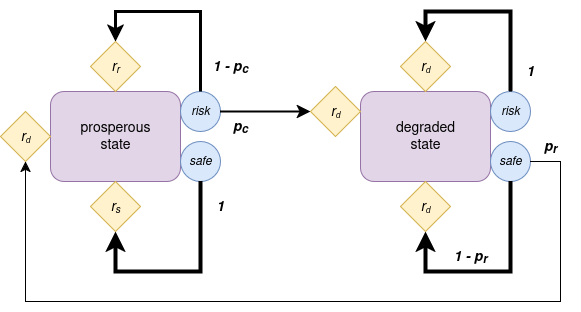

Let's implement a risk-reward dilemma.

First, we import what we need:

In [ ]:
 #| default_exp Environments.RiskRewardDilemma

In [ ]:
 #| hide
# Imports for the nbdev development environment
import nbdev
from nbdev.showdoc import *
from fastcore.basics import patch

In [ ]:
# imports for testing
import matplotlib.pyplot as plt
import numpy as np

# test agent
from pyCRLD.Agents.Base import abase
from pyCRLD.Agents.StrategyActorCritic import stratAC

# utils
from pyCRLD.Utils import FlowPlot as fp
from pyDDRL.Utils.Trajectories1D import trajectories_1D 
from pyDDRL.Utils.PhasePlot import phaseplot

In [ ]:
 #| export
from pyCRLD.Environments.Base import ebase
from pyCRLD.Utils.Helpers import make_variable_vector

from fastcore.utils import *
from fastcore.test import *

from typing import Iterable
import numpy as np

In [ ]:
 #| export
class RiskRewardDilemma(ebase):
    """
    Risk-Reward Dilemma.
    """ 

    def __init__(self,
                 pc:float,  # collapse probability
                 pr:float,  # recovery probability
                 rc:float,  # cautious reward
                 rr:float,  # risky reward
                 rd:float,  # reward in degraded state
                 asym=False,  # whether deg state is asymmetric
                 rdr=0.01):  # risky reward in deg state if deg state is asymmmetric
            
        self.N = 1
        self.M = 2
        self.Z = 2

        self.pc = pc
        self.pr = pr
        self.rc = rc
        self.rr = rr
        self.rd = rd
        if asym==True:
            self.rdr = rdr
        else:
            self.rdr = rd
        
        self.disttype = None
        
        self.Aset = self.actions()  # to have them available for the creation
        self.Sset = self.states()   # of the Transition and Reward Tensors

        self.state = 1 # initial state
        
        self.T = self.TransitionTensor()
        self.R = self.RewardTensor()
        self.F = np.array(self.FinalStates())
        # super().__init__()

In [ ]:
 #| export
@patch
def actions(self:RiskRewardDilemma):
    """The action set"""
    return ['c', 'r']

In [ ]:
 #| export
@patch
def states(self:RiskRewardDilemma):
    """The states set"""
    return ['p', 'd'] 

In [ ]:
 #| export
@patch
def TransitionTensor(self:RiskRewardDilemma):
    """Get the Transition Tensor."""
    dim = np.concatenate(([self.Z],
                          [self.M for _ in range(self.N)],
                          [self.Z]))
    Tsas = np.ones(dim) * (-1)

    for index, _ in np.ndenumerate(Tsas):
        Tsas[index] = self._transition_probability(index[0],
                                                   index[1],
                                                   index[2])
    return Tsas

@patch
def _transition_probability(self:RiskRewardDilemma,
                            s:int, # the state index
                            a:int, # index for action
                            s_:int  # the next-state index
                           ) -> float:  # transition probability 
    """
    Returns the transition probability for current state `s`, joint action `jA`, and next state `s_`.
    """
    transitionprob = 0

    if self.Sset[s] == 'p': # if we are in the prosperous state
        # determine the agent's choice
        choice = self.Aset[a]          
        if choice == 'c':  # cautious
            transitionprob = 0
        else:  # risky
            transitionprob = self.pc
            
        if self.Sset[s_] == 'd': # if we transitioned to the degraded state
            return transitionprob  # that is our transition probability
        else:  # back to the prosperous state
            return 1 - transitionprob
    
    else:  # if we are in the degraded state
        # determine the agent's choice
        choice = self.Aset[a]
        if choice == 'c':  # cautious
            transitionprob = self.pr
        else:  # risky
            transitionprob = 0
            
        if self.Sset[s_] == 'p': # if we transitioned to the prosperous state
            return transitionprob  # that is our transition probability
        else:  # back to the prosperous state
            return 1 - transitionprob

In [ ]:
 #| export
@patch
def RewardTensor(self:RiskRewardDilemma):
    """Get the Reward Tensor R[i,s,a1,...,aN,s']."""
    dim = np.concatenate(([self.N],
                          [self.Z],
                          [self.M],
                          [self.Z]))
    Risas = np.zeros(dim)

    for index, _ in np.ndenumerate(Risas):
        Risas[index] = self._reward(index[0], index[1], index[2],
                                    index[3])
    return Risas

@patch
def _reward(self:RiskRewardDilemma,
            i:int, # the agent index
            s:int, # the state index
            a:int, # the action index
            s_:int  # the next-state index
            ) -> float:  # reward value
    """
    Returns the reward value for agent `i` in current state `s`, under joint action `jA`, when transitioning to next state `s_`.
    """
    if self.Sset[s] == 'd' or self.Sset[s_] == 'd':  # if either current or next state is degraded
        # determine the agent's choice
        choice = self.Aset[a]  
        if choice == 'c':  # cautious
            reward = self.rd
        else:  # risky
            reward = self.rdr
        return reward 
    
    else:  # if current and next state are prosperous
        # determine the agent's choice
        choice = self.Aset[a]          
        if choice == 'c':  # cautious
            reward = self.rc
        else:  # risky
            reward = self.rr
        return reward

In [ ]:
 #| export
@patch
def id(self:RiskRewardDilemma):
    """
    Returns id string of environment
    """
    # Default
    pc = self.pc
    pr = self.pr
    rc = self.rc
    rr = self.rr
    rd = self.rd

    id = f"{self.__class__.__name__}_"+\
        f"{str(pc)}_{str(pr)}_{str(rc)}_{str(rr)}_{str(rd)}"
    return id

In [ ]:
 #| export
@patch
def FinalStates(self:RiskRewardDilemma):
    """Default final states: no final states"""
    return np.zeros(self.Z, dtype=int)

## Example

We use the following risk-reward dilemma, which we also implement below.

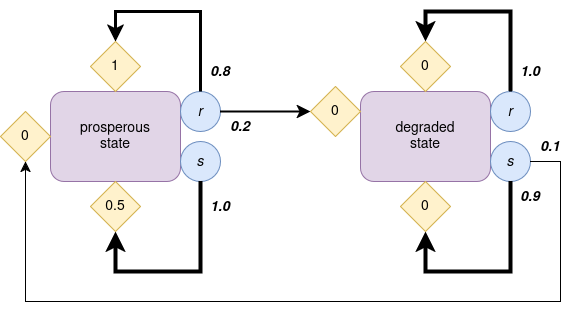

In [ ]:
# Define environment
rrd = RiskRewardDilemma(pc=0.2, pr=0.1, rc=0.5, rr=1, rd=0)

Now, we define an agent-environment interface comprised of an actor-critic agent playing the aforementioned task. This agent has a learning rate $\alpha=0.1$, and a discount factor $\gamma = 0.9$. 

In [ ]:
# Agent-environment interface
aei = stratAC(rrd,
              learning_rates=0.1,
              discount_factors=0.9,
              use_prefactor=True)

We plot the agent's deterministic trajectories in phase space on the flow plot below:

In [ ]:
# Figure
x = ([0], [0], [0])  # (i,s,a) to plot along the x-axis
y = ([0], [1], [0])  # (i,s,a) to plot along the y-axis

# Plot flow plot
fig, ax1 = plt.subplots(1, 1, figsize=(4, 4))
fp.plot_strategy_flow(aei, x, y, flowarrow_points = np.linspace(0.01 ,0.99, 9), 
                      NrRandom=16, axes=ax1)
# Sample trajectory
Xinit = np.ones((1,2,2)) * 0.4
Xinit[:,1,0] = 0.2
Xinit[:,:,1] = 1 - Xinit[:,:,0]  # initial strategy
trj, fpr = aei.trajectory(Xinit, Tmax=5000, tolerance=1e-6)  # compute traj
fp.plot_trajectories([trj], x, y, fprs=[fpr], axes=ax1, cols=['orange'])
ax1.set_title("Risk-reward dilemma")
ax1.set_xlabel("prob. safe action in prosp. state")
ax1.set_ylabel("prob. safe action in deg. state")
plt.show()

<Figure size 1200x1200 with 1 Axes>

In [ ]:
 #| hide
import nbdev; nbdev.nbdev_export()